In [2]:
import soundfile as sf

audio, sr = sf.read("data/day1/fake.aiff")
print("sample rate:", sr)
print("number of samples:", len(audio))
print("seconds:", len(audio) / sr)



sample rate: 22050
number of samples: 84956
seconds: 3.852879818594104


In [3]:
print(audio[:10])
print("smallest:", audio.min())
print("biggest:", audio.max())

[0.00100708 0.00100708 0.0010376  0.0010376  0.00112915 0.00115967
 0.00115967 0.0012207  0.00119019 0.0012207 ]
smallest: -0.38153076171875
biggest: 0.786376953125


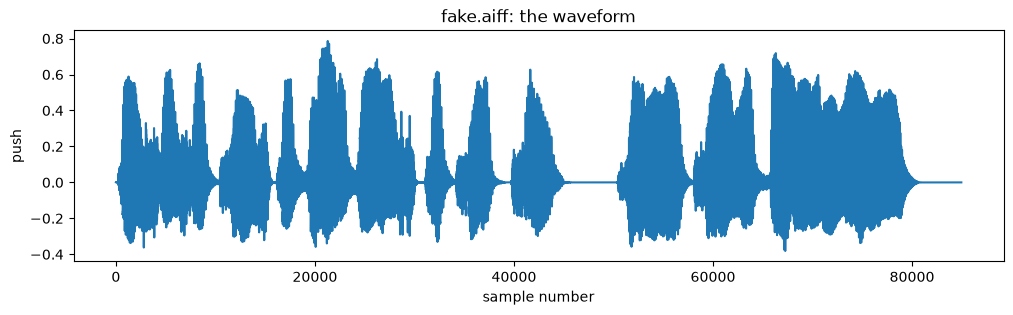

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 3))
plt.plot(audio)
plt.title("fake.aiff: the waveform")
plt.xlabel("sample number")
plt.ylabel("push")
plt.show()

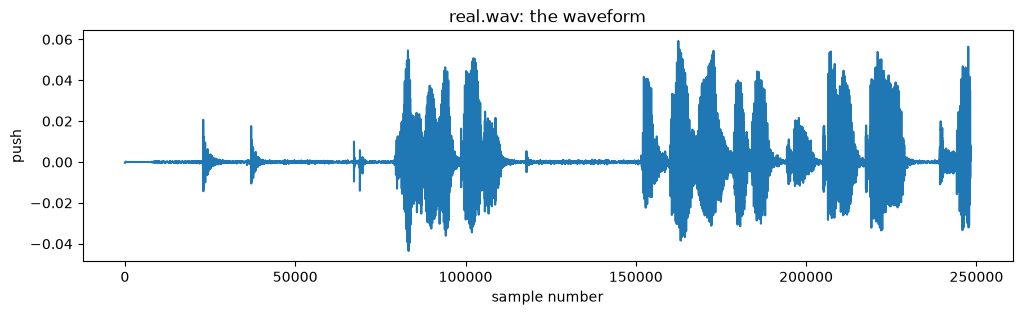

In [6]:
real, real_sr = sf.read("data/day1/real.wav")

plt.figure(figsize=(12, 3))
plt.plot(real)
plt.title("real.wav: the waveform")
plt.xlabel("sample number")
plt.ylabel("push")
plt.show()

In [7]:
import librosa

fake16, _ = librosa.load("data/day1/fake.aiff", sr=16000, mono=True)
real16, _ = librosa.load("data/day1/real.wav", sr=16000, mono=True)

print("fake:", len(fake16), "samples =", len(fake16) / 16000, "seconds")
print("real:", len(real16), "samples =", len(real16) / 16000, "seconds")

fake: 61647 samples = 3.8529375 seconds
real: 90056 samples = 5.6285 seconds


In [8]:
import numpy as np

LENGTH = 64600

def fix_length(x, length=LENGTH):
    if len(x) >= length:
        return x[:length]
    repeats = length // len(x) + 1
    return np.tile(x, repeats)[:length]

fake_fixed = fix_length(fake16)
real_fixed = fix_length(real16)

print("fake:", len(fake_fixed))
print("real:", len(real_fixed))

fake: 64600
real: 64600


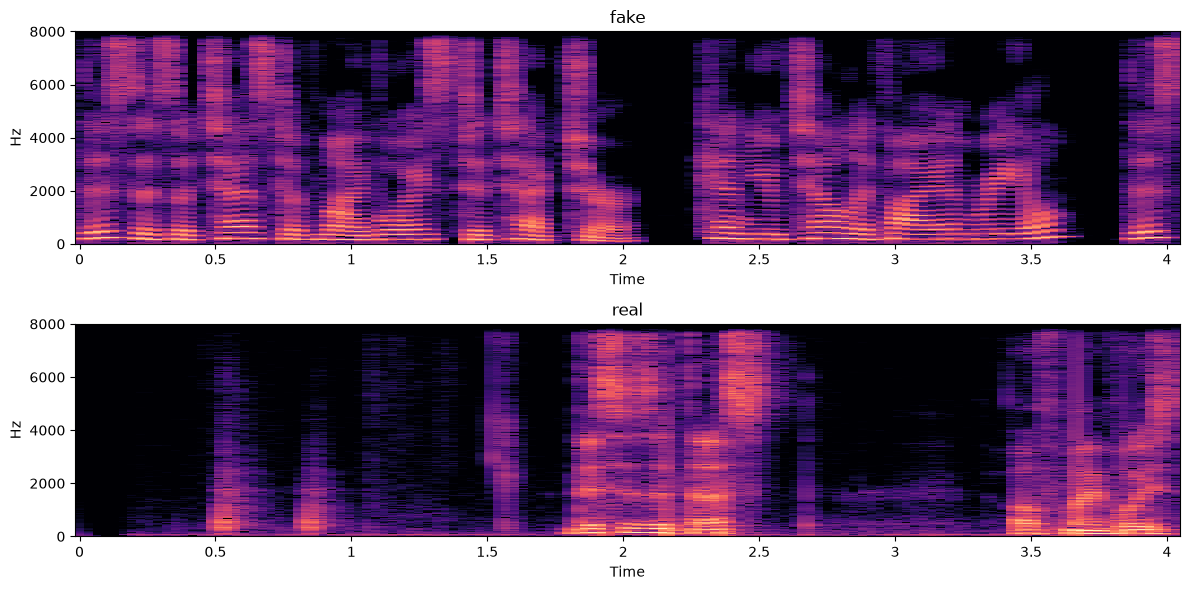

In [9]:
import librosa.display

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

for ax, clip, name in [(axes[0], fake_fixed, "fake"), (axes[1], real_fixed, "real")]:
    spec = librosa.amplitude_to_db(np.abs(librosa.stft(clip)), ref=np.max)
    librosa.display.specshow(spec, sr=16000, x_axis="time", y_axis="hz", ax=ax)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [1]:
import numpy as np
]

scores = np.array([0.10, 0.35, 0.62, 0.91, 0.70, 0.40])
labels = np.array([0,    0,    0,    1,    1,    1   ])   # 0 = real, 1 = fake

print(scores > 0.5)

[False False  True  True  True False]


In [2]:
predicted_fake = scores > 0.5

print(predicted_fake[labels == 0])

[False False  True]


In [3]:
false_alarm_rate = predicted_fake[labels == 0].mean()
print(false_alarm_rate)


0.3333333333333333


In [5]:
miss_rate = miss_rate = (~predicted_fake)[labels == 1].mean()
print(miss_rate)

0.3333333333333333


In [7]:
def rates_at(threshold):
    predicted_fake = scores > threshold
    false_alarm_rate = predicted_fake[labels == 0].mean()
    miss_rate = (~predicted_fake)[labels == 1].mean()
    return false_alarm_rate, miss_rate

print(rates_at(0.5))
print(rates_at(0.3))
print(rates_at(0.8))

(np.float64(0.3333333333333333), np.float64(0.3333333333333333))
(np.float64(0.6666666666666666), np.float64(0.0))
(np.float64(0.0), np.float64(0.6666666666666666))


In [8]:
def find_eer():
    best_gap = 1.0
    for t in np.linspace(0, 1, 101):
        fa, miss = rates_at(t)
        gap = abs(fa - miss)
        if gap < best_gap:
            best_gap = gap
            best_t = t
            best_eer = (fa + miss) / 2
    return best_eer, best_t

print(find_eer())

(np.float64(0.3333333333333333), np.float64(0.4))


In [10]:
import numpy as np


def rates_at(scores, labels, threshold):
    predicted_fake = scores > threshold
    false_alarm_rate = predicted_fake[labels == 0].mean()
    miss_rate = (~predicted_fake)[labels == 1].mean()
    return false_alarm_rate, miss_rate


def compute_eer(scores, labels):
    best_gap = 1.0
    for t in np.linspace(0, 1, 101):
        fa, miss = rates_at(scores, labels, t)
        gap = abs(fa - miss)
        if gap < best_gap:
            best_gap = gap
            best_t = t
            best_eer = (fa + miss) / 2
    return best_eer, best_t
    

In [11]:
from voiceguard.metrics import compute_eer

print(compute_eer(scores, labels))

(np.float64(0.3333333333333333), np.float64(0.4))
